# Prototype 25 — decision-model candidates vs Jev (#296 Phase 0, round 2)

**Why a round 2.** In nb24, CLM-8B agreed with Jev on only 10% of top picks (median Spearman 0.18). Looking at the raw scores, CLM's were squeezed into 0.54–0.64 in every scenario. The cause was how we asked, not only the model: CLM compares the state against two candidate texts, `"Yes. This is true: <question>"` and `"No. This is false: <question>"`. We put the whole outfit JSON inside the question, so both candidates were near-identical, and CLM is trained on prose, not JSON (`src/clm/schema.py`).

**Candidates** (the #296 matrix, minus the heavy GLM track). Everything runs on the RunPod A6000, or as a hosted API:

| name | what | where |
|---|---|---|
| `jev` | reference: production question format | OpenRouter |
| `clm-raw` | nb24's format again, for continuity | pod `clm-serve` |
| `clm-prose` | outfit as prose, short yes/no criteria | pod `clm-serve` |
| `clm-choice` | one Choice over all outfits (CLM's native "rank candidates") | pod `clm-serve` (suggest only) |
| `qwen3-8b` | Qwen3-8B as a judge: 0–9 rating, expected value over digit probabilities | pod vLLM (tunnelled to :8001) |
| `prismnli` | PrismNLI-0.4B entailment, "this outfit is a good choice…" | pod :8010 |
| `gemini-flash` | Gemini 2.5 Flash returning a probability per outfit (like `DECISIONS_PROVIDER=llm`) | Google API |

Same 10 scenarios (nb20) and 4 collections (nb23) as nb24. Jev is the reference, not ground truth: the report shows every candidate's top 3 with photos, so you judge.

**Run:** tunnels `8700` (CLM), `8001` (Qwen judge) and `8010` (PrismNLI) to the pod; `CLM_API_KEY` is the key for all three pod services. The last section is Qwen-Image.

## 1. Setup — imports, env, paths

In [1]:
from __future__ import annotations

import base64
import io
import json
import math
import os
import sqlite3
import statistics
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

REPO_ROOT = Path.cwd().parent.parent if Path.cwd().name == "notebooks" else Path.cwd()

# Load .env if present (same convention as nb20/nb23)
env_path = REPO_ROOT / ".env"
if env_path.exists():
    for line in env_path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        k, v = line.split("=", 1)
        os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

CLOSET_DATA_DIR = Path(os.environ.get("CLOSET_DATA_DIR", str(REPO_ROOT / ".closet")))
if not (CLOSET_DATA_DIR / "closet.db").exists():
    CLOSET_DATA_DIR = Path.home() / ".closet"
CLOSET_DB = CLOSET_DATA_DIR / "closet.db"
OUT_DIR = Path(os.environ.get("NB25_OUT_DIR", str(REPO_ROOT / "prototypes" / "outputs" / "25")))
OUT_DIR.mkdir(parents=True, exist_ok=True)

JEV_URL = os.environ.get("JEV_URL", "https://openrouter.ai/api/alpha/decisions")
JEV_KEY = os.environ.get("OPENROUTER_API_KEY", "")
JEV_MODEL = "typesafe/jev-1.13"
CLM_URL = os.environ.get("CLM_URL", "")
CLM_KEY = os.environ.get("CLM_API_KEY", "")

print(f"CLOSET_DB: {CLOSET_DB}  exists={CLOSET_DB.exists()}")
print(f"OUT_DIR:   {OUT_DIR}")
print(f"Jev:       {'key set' if JEV_KEY else 'NO OPENROUTER_API_KEY — Jev skipped'}")
print(f"CLM:       {CLM_URL or 'CLM_URL not set — CLM skipped (dry run)'}")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


CLOSET_DB: .closet/closet.db  exists=True
OUT_DIR:   prototypes/outputs/25
Jev:       key set
CLM:       http://localhost:8700/v1/systemone


## 2. One decisions client for both models

Both speak TypeSafe: `POST {state, questions}` → `answers[qid]`. Two differences handled here:
- Jev needs `model` + `provider: {zdr: true}` (same as production); CLM takes neither.
- `clm-serve` answers carry **no `type`** field (`{noul: 0.41}`), so answers are read by the question asked.

In [2]:
import urllib.request
import urllib.error


def call_decisions(url: str, key: str, state, questions: dict, *, extra: dict | None = None, timeout_s: int = 60) -> dict:
    """Returns {ok, latency_s, answers, usage, error?}."""
    if not url:
        return {"ok": False, "error": "no url", "latency_s": 0.0, "answers": {}, "usage": {}}
    body = json.dumps({**(extra or {}), "state": state, "questions": questions}).encode()
    headers = {"Content-Type": "application/json"}
    if key:
        headers["Authorization"] = f"Bearer {key}"
    req = urllib.request.Request(url, data=body, method="POST", headers=headers)
    t0 = time.perf_counter()
    try:
        with urllib.request.urlopen(req, timeout=timeout_s) as resp:
            payload = json.loads(resp.read())
        return {"ok": True, "latency_s": time.perf_counter() - t0,
                "answers": payload.get("answers") or {}, "usage": payload.get("usage") or {}}
    except urllib.error.HTTPError as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0, "answers": {}, "usage": {},
                "error": f"HTTP {e.code}: {e.read()[:300].decode(errors='replace')}"}
    except Exception as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0, "answers": {}, "usage": {},
                "error": f"{type(e).__name__}: {e}"}


MODELS = {}
if JEV_KEY:
    MODELS["jev"] = lambda state, qs: call_decisions(JEV_URL, JEV_KEY, state, qs, extra={"model": JEV_MODEL, "provider": {"zdr": True}})
if CLM_URL:
    MODELS["clm"] = lambda state, qs: call_decisions(CLM_URL, CLM_KEY, state, qs)


def noul_scores(result: dict) -> dict[str, float]:
    """{qid: noul} from either model's answers."""
    out = {}
    for qid, a in (result.get("answers") or {}).items():
        if isinstance(a, dict) and isinstance(a.get("noul"), (int, float)):
            out[qid] = float(a["noul"])
    return out


# Probe each model once
probe_q = {"is_cold": {"type": "noul", "instructions": "Is the temperature below 15°C?"}}
for name, call in MODELS.items():
    r = call("It is 5°C and raining.", probe_q)
    print(f"{name:4s} ok={r['ok']}  noul={noul_scores(r)}  {r['latency_s']:.2f}s  {r.get('error') or ''}")

jev  ok=True  noul={'is_cold': 0.99}  2.37s  
clm  ok=False  noul={}  0.15s  ConnectionResetError: [Errno 54] Connection reset by peer


## 3. Data loaders — items, outfits (from nb20), photos (from nb23)

Active user: self   items: 43   outfits with items: 42



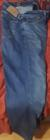
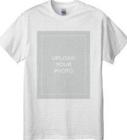
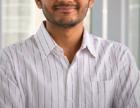
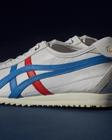

In [3]:
def pick_active_user(db_path: Path) -> str | None:
    if not db_path.exists():
        return None
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    row = conn.execute("SELECT user_id, COUNT(*) c FROM items GROUP BY user_id ORDER BY c DESC LIMIT 1").fetchone()
    conn.close()
    return row[0] if row else None


def _rows(db_path: Path, sql: str, args: tuple) -> list[dict]:
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    conn.row_factory = sqlite3.Row
    rows = [dict(r) for r in conn.execute(sql, args).fetchall()]
    conn.close()
    return rows


def _json_fields(d: dict, fields: tuple[str, ...]) -> dict:
    for f in fields:
        try:
            d[f] = json.loads(d[f]) if d[f] else []
        except (json.JSONDecodeError, TypeError):
            d[f] = []
    return d


ACTIVE_USER = pick_active_user(CLOSET_DB)
items = [_json_fields(r, ("colors", "season", "occasion", "tags")) for r in _rows(CLOSET_DB, """
    SELECT id, category, subcategory, primary_color, colors, brand, material, season,
           occasion, tags, ai_description, image_uri, wear_context
    FROM items WHERE user_id = ? ORDER BY id""", (ACTIVE_USER,))] if ACTIVE_USER else []
outfits = [_json_fields(r, ("item_ids", "season", "tags")) for r in _rows(CLOSET_DB, """
    SELECT id, name, item_ids, occasion, season, tags FROM outfits WHERE user_id = ? ORDER BY id""", (ACTIVE_USER,))] if ACTIVE_USER else []
items_by_id = {it["id"]: it for it in items}
outfits = [o for o in outfits if any(i in items_by_id for i in o["item_ids"])]
print(f"Active user: {ACTIVE_USER}   items: {len(items)}   outfits with items: {len(outfits)}")
assert len(outfits) >= 2, "Need at least 2 saved outfits (npm run seed:dev, or save some in the PWA)."

try:
    from PIL import Image
    HAVE_PIL = True
except ImportError:
    HAVE_PIL = False
_IMG_CACHE: dict[str, str] = {}


def image_data_url(image_uri: str | None, *, max_dim: int = 140) -> str:
    """Inline thumbnail. Photos live under users/<id>/images/…, or images/… for the legacy 'self' user."""
    if not image_uri:
        return ""
    if image_uri in _IMG_CACHE:
        return _IMG_CACHE[image_uri]
    path = next((p for p in (CLOSET_DATA_DIR / "users" / str(ACTIVE_USER) / image_uri, CLOSET_DATA_DIR / image_uri) if p.exists()), None)
    if path is None:
        _IMG_CACHE[image_uri] = ""
        return ""
    raw = path.read_bytes()
    if HAVE_PIL:
        try:
            img = Image.open(io.BytesIO(raw))
            img.thumbnail((max_dim, max_dim))
            buf = io.BytesIO()
            img.convert("RGB").save(buf, format="JPEG", quality=75)
            raw = buf.getvalue()
        except Exception:
            pass
    _IMG_CACHE[image_uri] = "data:image/jpeg;base64," + base64.b64encode(raw).decode()
    return _IMG_CACHE[image_uri]


def outfit_image_html(outfit: dict, *, max_items: int = 6, size: int = 56) -> str:
    cells = []
    for iid in outfit.get("item_ids", [])[:max_items]:
        url = image_data_url((items_by_id.get(iid) or {}).get("image_uri"))
        if url:
            cells.append(f"<img src='{url}' style='height:{size}px;width:{size}px;object-fit:cover;border:1px solid #ddd;border-radius:6px;margin:2px'/>")
    return "<div style='display:flex;flex-wrap:wrap'>" + "".join(cells) + "</div>"


display(HTML(f"<b>{outfits[0]['name']}</b>" + outfit_image_html(outfits[0])))

## 4. Questions — built like production

`src/ai/decisionText.ts` + `suggestOutfitQuestion` in `src/ai/suggest.ts`: one Noul per outfit, instruction text + the outfit's JSON (item fields, description capped at 200 chars). Both models get these exact strings.

CLM reads at most **2048 tokens** per text (`clm-serve --max-tokens`). Vastra shrinks longer questions before sending (#351); here we just show the longest one so you can see if any outfit is near the limit (~3 characters per token).

In [4]:
def item_blob(it: dict) -> dict:
    desc = (it.get("ai_description") or "").strip()
    blob = {
        "category": it.get("category"), "subcategory": it.get("subcategory"), "primaryColor": it.get("primary_color"),
        "colors": it.get("colors"), "material": it.get("material"), "brand": it.get("brand"),
        "season": it.get("season"), "occasion": it.get("occasion"), "tags": it.get("tags"),
        "wearContext": it.get("wear_context"), "description": (desc[:199] + "…") if len(desc) > 200 else (desc or None),
    }
    return {k: v for k, v in blob.items() if v not in (None, [], "")}


def outfit_blob(o: dict) -> dict:
    head = {"name": o.get("name"), "occasion": o.get("occasion"), "season": o.get("season"), "tags": o.get("tags")}
    head = {k: v for k, v in head.items() if v not in (None, [], "")}
    return {**head, "items": [item_blob(items_by_id[i]) for i in o["item_ids"] if i in items_by_id]}


def suggest_question(o: dict) -> dict:
    return {"type": "noul", "instructions": f"Is this outfit a good pick for the given context? Outfit JSON: {json.dumps(outfit_blob(o))}"}


SUGGEST_QUESTIONS = {f"q_{o['id']}": suggest_question(o) for o in outfits}
longest = max(len(q["instructions"]) for q in SUGGEST_QUESTIONS.values())
print(f"{len(SUGGEST_QUESTIONS)} questions; longest {longest} chars ≈ {longest // 3} tokens (limit 2048)")

42 questions; longest 1055 chars ≈ 351 tokens (limit 2048)


## 5. Scenarios — nb20's 10 suggest fixtures, nb23's 4 collections

In [5]:
FIXTURES = [
    {"id": "rainy_work_morning", "weather": {"temperature": 13, "condition": "Rainy", "precipitation": 5.2, "windSpeed": 15}, "occasion": "office", "theme": None, "timeOfDay": "morning", "dayOfWeek": "Tuesday"},
    {"id": "hot_brunch_weekend", "weather": {"temperature": 32, "condition": "Sunny", "precipitation": 0, "windSpeed": 5}, "occasion": "brunch", "theme": "weekend, want to feel breezy", "timeOfDay": "midday", "dayOfWeek": "Saturday"},
    {"id": "cold_formal_interview", "weather": {"temperature": -2, "condition": "Snow", "precipitation": 1, "windSpeed": 20}, "occasion": "job interview", "theme": None, "timeOfDay": "morning", "dayOfWeek": "Monday"},
    {"id": "warm_casual_errands", "weather": {"temperature": 22, "condition": "Cloudy", "precipitation": 0, "windSpeed": 8}, "occasion": "running errands", "theme": None, "timeOfDay": "afternoon", "dayOfWeek": "Saturday"},
    {"id": "mild_evening_date", "weather": {"temperature": 17, "condition": "Clear", "precipitation": 0, "windSpeed": 3}, "occasion": "dinner date", "theme": "want to look put-together but not overdressed", "timeOfDay": "evening", "dayOfWeek": "Friday"},
    {"id": "cold_wfh", "weather": {"temperature": 4, "condition": "Cloudy", "precipitation": 0, "windSpeed": 12}, "occasion": "working from home", "theme": "comfortable but presentable for video calls", "timeOfDay": "morning", "dayOfWeek": "Wednesday"},
    {"id": "humid_wedding", "weather": {"temperature": 28, "condition": "Humid", "precipitation": 0, "windSpeed": 4}, "occasion": "outdoor wedding", "theme": None, "timeOfDay": "afternoon", "dayOfWeek": "Sunday"},
    {"id": "windy_outdoor_walk", "weather": {"temperature": 10, "condition": "Windy", "precipitation": 0, "windSpeed": 35}, "occasion": "long walk in the park", "theme": None, "timeOfDay": "midday", "dayOfWeek": "Sunday"},
    {"id": "cool_workout", "weather": {"temperature": 15, "condition": "Clear", "precipitation": 0, "windSpeed": 6}, "occasion": "outdoor run", "theme": None, "timeOfDay": "morning", "dayOfWeek": "Thursday"},
    {"id": "cold_evening_out", "weather": {"temperature": 6, "condition": "Clear", "precipitation": 0, "windSpeed": 10}, "occasion": "concert", "theme": "want to stand out a bit", "timeOfDay": "evening", "dayOfWeek": "Friday"},
]


def fixture_state(fx: dict) -> dict:
    """Same shape as buildJevState in src/ai/suggest.ts."""
    w = fx["weather"]
    return {
        "weather": {"temperature_c": w["temperature"], "condition": w["condition"], "precipitation_mm": w.get("precipitation", 0), "wind_kmh": w.get("windSpeed", 0)},
        "occasion": fx.get("occasion"), "time_of_day": fx.get("timeOfDay"), "day_of_week": fx.get("dayOfWeek"), "theme": fx.get("theme"),
    }


TARGET_COLLECTIONS = [
    {
        "key": "workwear_rotation",
        "name": "Workwear Rotation",
        "description": (
            "Office-appropriate outfits for a professional workplace. Polished, put-together, "
            "tailored pieces. Includes blazers, dress shirts, structured trousers, and dress shoes. "
            "Excludes athleisure, streetwear, and weekend-casual looks."
        ),
    },
    {
        "key": "cold_weather",
        "name": "Cold Weather",
        "description": (
            "Outfits that keep you warm in winter or late fall — heavy coats, wool layers, sweaters, "
            "thermal fabrics, boots. Excludes lightweight or summer-only pieces."
        ),
    },
    {
        "key": "weekend_casual",
        "name": "Weekend Casual",
        "description": (
            "Relaxed outfits for weekends and errands. Comfortable, low-effort, includes jeans, "
            "t-shirts, hoodies, sneakers. Excludes formal, business, or dressy pieces."
        ),
    },
    {
        "key": "outdoor_rugged",
        "name": "Outdoor Rugged",
        "description": (
            "Outfits built for the outdoors — hiking, walking, active use. Utility jackets, "
            "work boots, sturdy fabrics, layered warmth. Excludes formal, dressy, or delicate pieces."
        ),
    },
]


pd.DataFrame([{k: fx[k] for k in ("id", "occasion", "timeOfDay", "dayOfWeek")} | {"temp_c": fx["weather"]["temperature"]} for fx in FIXTURES])

,id,occasion,timeOfDay,dayOfWeek,temp_c
0,rainy_work_morning,office,morning,Tuesday,13
1,hot_brunch_weekend,brunch,midday,Saturday,32
2,cold_formal_interview,job interview,morning,Monday,-2
3,warm_casual_errands,running errands,afternoon,Saturday,22
4,mild_evening_date,dinner date,evening,Friday,17
5,cold_wfh,working from home,morning,Wednesday,4
6,humid_wedding,outdoor wedding,afternoon,Sunday,28
7,windy_outdoor_walk,long walk in the park,midday,Sunday,10
8,cool_workout,outdoor run,morning,Thursday,15
9,cold_evening_out,concert,evening,Friday,6


## 6. Candidates

Each candidate turns a scenario (or a collection) into `{question_id: score}`, where a higher score means a better pick. The prose helper is a port of CLM's own `to_text`, so every non-Jev candidate sees the same prose.

In [6]:
POD_KEY = os.environ.get("CLM_API_KEY", "")
QWEN_JUDGE_URL = os.environ.get("QWEN_JUDGE_URL", "http://localhost:8001/v1")
PRISM_URL = os.environ.get("PRISM_URL", "http://localhost:8010")
GEMINI_KEY = os.environ.get("GEMINI_API_KEY", "")


def prose(x, indent: int = 0) -> str:
    """CLM's to_text: objects → `key: value`, lists → `- item` lines."""
    if x is None: return ""
    if isinstance(x, str): return x
    if isinstance(x, bool): return "true" if x else "false"
    if isinstance(x, (int, float)): return str(x)
    pad = " " * indent
    if isinstance(x, dict):
        parts = [f"{pad}{k}:\n{prose(v, indent + 2)}" if isinstance(v, (dict, list)) and v else f"{pad}{k}: {prose(v)}" for k, v in x.items()]
        return ("\n\n" if indent == 0 else "\n").join(parts)
    if isinstance(x, list):
        return "\n".join(f"{pad}-\n{prose(v, indent + 2)}" if isinstance(v, (dict, list)) and v else f"{pad}- {prose(v)}" for v in x)
    return json.dumps(x)


def scenario_prose(fx: dict) -> str:
    w = fx["weather"]
    lines = [f"Weather today: {w['temperature']}°C, {w['condition']}, {w.get('precipitation', 0)} mm rain, wind {w.get('windSpeed', 0)} km/h.",
             f"Occasion: {fx.get('occasion')}.", f"Time: {fx.get('timeOfDay')} on a {fx.get('dayOfWeek')}."]
    if fx.get("theme"):
        lines.append(f"Note: {fx['theme']}.")
    return "\n".join(lines)


OUTFIT_PROSE = {f"q_{o['id']}": prose(outfit_blob(o)) for o in outfits}


def post_json(url: str, body: dict, *, key: str = "", headers: dict | None = None, timeout_s: int = 120) -> dict:
    h = {"Content-Type": "application/json", **(headers or {})}
    if key:
        h["Authorization"] = f"Bearer {key}"
    req = urllib.request.Request(url, data=json.dumps(body).encode(), method="POST", headers=h)
    with urllib.request.urlopen(req, timeout=timeout_s) as resp:
        return json.loads(resp.read())


# ── Jev + CLM (TypeSafe) ─────────────────────────────────────────────────────
def jev_suggest(fx): return noul_scores(MODELS["jev"](fixture_state(fx), SUGGEST_QUESTIONS))
def clm_raw_suggest(fx): return noul_scores(MODELS["clm"](fixture_state(fx), SUGGEST_QUESTIONS))

GOOD = {"true": "Yes, a good pick: it suits this weather, occasion and time of day.",
        "false": "No, a poor pick for this weather, occasion or time of day."}


def clm_prose_suggest(fx):
    qs = {qid: {"type": "noul", "instructions": f"Outfit:\n{p}\n\nIs this outfit a good pick for today?", "criteria": GOOD} for qid, p in OUTFIT_PROSE.items()}
    return noul_scores(MODELS["clm"](scenario_prose(fx), qs))


def clm_choice_suggest(fx):
    r = MODELS["clm"](scenario_prose(fx), {"best": {"type": "choice", "instructions": "Which of my saved outfits should I wear today?", "criteria": OUTFIT_PROSE}})
    return {k: float(v) for k, v in ((r.get("answers") or {}).get("best") or {}).get("probabilities", {}).items()}


def coll_state(coll): return f"Collection: {coll['name']}\n{coll['description']}"
def coll_questions_json(coll): return {f"q_{o['id']}": {"type": "noul", "instructions": f"Does this outfit belong in this collection? Outfit JSON: {json.dumps(outfit_blob(o))}"} for o in outfits}


def jev_coll(coll): return noul_scores(MODELS["jev"](coll_state(coll), coll_questions_json(coll)))
def clm_raw_coll(coll): return noul_scores(MODELS["clm"](coll_state(coll), coll_questions_json(coll)))


def clm_prose_coll(coll):
    crit = {"true": "Yes, this outfit belongs in this collection.", "false": "No, this outfit doesn't belong in this collection."}
    qs = {qid: {"type": "noul", "instructions": f"Outfit:\n{p}\n\nDoes this outfit belong in this collection?", "criteria": crit} for qid, p in OUTFIT_PROSE.items()}
    return noul_scores(MODELS["clm"](coll_state(coll), qs))


# ── Qwen3-8B judge: a 0–9 rating read from the digit probabilities ───────────
# Asking Yes/No saturates (P(no) ≈ 1.0 for most outfits), so ties everywhere.
# Instead: "rate 0–9", then take the expected value over the digit tokens'
# probabilities (G-Eval style), scaled to 0–1. Smooth and rankable.
def qwen_yes(context: str, question: str) -> float:
    r = post_json(f"{QWEN_JUDGE_URL}/chat/completions", {
        "model": "qwen3-8b-chat", "max_tokens": 1, "temperature": 0, "logprobs": True, "top_logprobs": 20,
        "chat_template_kwargs": {"enable_thinking": False},
        "messages": [{"role": "system", "content": "You are a fashion stylist. Answer with a single digit from 0 (terrible) to 9 (perfect)."},
                     {"role": "user", "content": f"{context}\n\n{question} Rate it 0-9."}],
    }, key=POD_KEY)
    top = r["choices"][0]["logprobs"]["content"][0]["top_logprobs"]
    digits = {}
    for t in top:
        tok = t["token"].strip()
        if len(tok) == 1 and tok.isdigit():
            digits[int(tok)] = digits.get(int(tok), 0.0) + math.exp(t["logprob"])
    z = sum(digits.values())
    return sum(d * p for d, p in digits.items()) / z / 9 if z else 0.5


def qwen_suggest(fx):
    ctx = scenario_prose(fx)
    with ThreadPoolExecutor(max_workers=16) as pool:
        vals = pool.map(lambda kv: qwen_yes(f"{ctx}\n\nOutfit:\n{kv[1]}", "Is this outfit a good pick for today?"), OUTFIT_PROSE.items())
        return dict(zip(OUTFIT_PROSE, vals))


def qwen_coll(coll):
    ctx = coll_state(coll)
    with ThreadPoolExecutor(max_workers=16) as pool:
        vals = pool.map(lambda kv: qwen_yes(f"{ctx}\n\nOutfit:\n{kv[1]}", "Does this outfit belong in this collection?"), OUTFIT_PROSE.items())
        return dict(zip(OUTFIT_PROSE, vals))


# ── PrismNLI: P(entailment) ──────────────────────────────────────────────────
def prism(pairs): return post_json(f"{PRISM_URL}/entail", {"pairs": pairs}, key=POD_KEY)["entail"]


def prism_suggest(fx):
    ctx = scenario_prose(fx)
    pairs = [[f"{ctx}\n\nOutfit:\n{p}", "This outfit is a good choice for this weather, occasion and time of day."] for p in OUTFIT_PROSE.values()]
    return dict(zip(OUTFIT_PROSE, prism(pairs)))


def prism_coll(coll):
    pairs = [[f"Outfit:\n{p}", f"This outfit belongs in the '{coll['name']}' collection: {coll['description']}"] for p in OUTFIT_PROSE.values()]
    return dict(zip(OUTFIT_PROSE, prism(pairs)))


# ── Gemini Flash: one probability per outfit (the `llm` provider's prompt) ───
def gemini_probs(context: str, questions: dict[str, str]) -> dict[str, float]:
    lines = "\n".join(f"- {qid}: {q}" for qid, q in questions.items())
    prompt = (f"You answer yes/no questions about the state below with calibrated probabilities.\n\nState:\n{context}\n\n"
              f"Questions (id: question):\n{lines}\n\nReturn ONLY a JSON object mapping every question id to the probability (0 to 1) that the answer is yes.")
    r = post_json("https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent",
                  {"contents": [{"role": "user", "parts": [{"text": prompt}]}], "generationConfig": {"responseMimeType": "application/json", "temperature": 0}},
                  headers={"x-goog-api-key": GEMINI_KEY}, timeout_s=180)
    data = json.loads(r["candidates"][0]["content"]["parts"][0]["text"])
    return {k: min(1.0, max(0.0, float(v))) for k, v in data.items() if k in questions and isinstance(v, (int, float))}


def gemini_suggest(fx): return gemini_probs(scenario_prose(fx), {qid: f"Is this outfit a good pick for today? Outfit: {p}" for qid, p in OUTFIT_PROSE.items()})
def gemini_coll(coll): return gemini_probs(coll_state(coll), {qid: f"Does this outfit belong in this collection? Outfit: {p}" for qid, p in OUTFIT_PROSE.items()})


def reachable(url: str) -> bool:
    try:
        urllib.request.urlopen(url, timeout=5)
        return True
    except urllib.error.HTTPError:
        return True  # it answered
    except Exception:
        return False


CANDIDATES = {}
if "jev" in MODELS: CANDIDATES["jev"] = (jev_suggest, jev_coll)
if "clm" in MODELS:
    CANDIDATES["clm-raw"] = (clm_raw_suggest, clm_raw_coll)
    CANDIDATES["clm-prose"] = (clm_prose_suggest, clm_prose_coll)
    CANDIDATES["clm-choice"] = (clm_choice_suggest, None)
if reachable(f"{QWEN_JUDGE_URL}/models"): CANDIDATES["qwen3-8b"] = (qwen_suggest, qwen_coll)
if reachable(PRISM_URL): CANDIDATES["prismnli"] = (prism_suggest, prism_coll)
if GEMINI_KEY: CANDIDATES["gemini-flash"] = (gemini_suggest, gemini_coll)
print("Candidates:", ", ".join(CANDIDATES))

Candidates: jev, clm-raw, clm-prose, clm-choice, qwen3-8b, prismnli, gemini-flash


## 7. Run every candidate on the same scenarios and collections

In [7]:
suggest_scores, coll_scores, latency = {}, {}, {}
for name, (fs, fc) in CANDIDATES.items():
    t0 = time.perf_counter()
    for fx in FIXTURES:
        t = time.perf_counter()
        try:
            suggest_scores[(name, fx["id"])] = fs(fx)
        except Exception as e:
            suggest_scores[(name, fx["id"])] = {}
            print(f"[{name}] {fx['id']}: {type(e).__name__}: {e}")
        latency.setdefault(name, []).append(time.perf_counter() - t)
    for coll in TARGET_COLLECTIONS if fc else []:
        try:
            coll_scores[(name, coll["key"])] = fc(coll)
        except Exception as e:
            coll_scores[(name, coll["key"])] = {}
            print(f"[{name}] {coll['key']}: {type(e).__name__}: {e}")
    print(f"{name:13s} done in {time.perf_counter() - t0:6.1f}s   median per scenario {statistics.median(latency[name]):.2f}s")

jev           done in    4.7s   median per scenario 0.34s


clm-raw       done in   12.3s   median per scenario 0.46s


clm-prose     done in   27.8s   median per scenario 1.95s


clm-choice    done in    6.6s   median per scenario 0.51s


qwen3-8b      done in   30.1s   median per scenario 2.12s


prismnli      done in   10.1s   median per scenario 0.66s


gemini-flash  done in  509.2s   median per scenario 36.99s


## 8. Agreement with Jev

- **Suggest:** CLM-style "is my #1 in Jev's top 3", same #1, and Spearman over the whole order.
- **Collections:** same accept/reject at 0.5 (calibration differs per model, so this one is harsh), plus rank agreement (Spearman), which ignores calibration.

In [8]:
def spearman(a: dict, b: dict) -> float:
    shared = [q for q in a if q in b]
    return pd.Series([a[q] for q in shared]).corr(pd.Series([b[q] for q in shared]), method="spearman") if len(shared) > 1 else float("nan")


def ranked(s: dict) -> list[str]:
    return sorted(s, key=s.get, reverse=True)


rows = []
for name in CANDIDATES:
    if name == "jev" or "jev" not in CANDIDATES:
        continue
    top13, same1, rhos = [], [], []
    for fx in FIXTURES:
        j, c = suggest_scores.get(("jev", fx["id"])) or {}, suggest_scores.get((name, fx["id"])) or {}
        if j and c:
            top13.append(ranked(c)[0] in ranked(j)[:3]); same1.append(ranked(c)[0] == ranked(j)[0]); rhos.append(spearman(j, c))
    same_call, crhos = [], []
    for coll in TARGET_COLLECTIONS:
        j, c = coll_scores.get(("jev", coll["key"])) or {}, coll_scores.get((name, coll["key"])) or {}
        if j and c:
            same_call += [(j[q] >= 0.5) == (c[q] >= 0.5) for q in j if q in c]; crhos.append(spearman(j, c))
    rows.append({"candidate": name,
                 "suggest_top1_in_jev_top3": sum(top13) / len(top13) if top13 else float("nan"),
                 "suggest_same_top1": sum(same1) / len(same1) if same1 else float("nan"),
                 "suggest_spearman": statistics.median(rhos) if rhos else float("nan"),
                 "coll_same_call": sum(same_call) / len(same_call) if same_call else float("nan"),
                 "coll_spearman": statistics.median(crhos) if crhos else float("nan"),
                 "s_per_scenario": statistics.median(latency[name])})
compare_df = pd.DataFrame(rows).sort_values("suggest_spearman", ascending=False)
compare_df.style.format({c: "{:.2f}" for c in compare_df.columns if c != "candidate"})

,candidate,suggest_top1_in_jev_top3,suggest_same_top1,suggest_spearman,coll_same_call,coll_spearman,s_per_scenario
3,qwen3-8b,0.80,0.30,0.76,0.64,0.83,2.12
5,gemini-flash,0.50,0.20,0.68,0.86,0.88,36.99
1,clm-prose,0.40,0.10,0.63,0.61,0.80,1.95
0,clm-raw,0.10,0.00,0.16,0.32,0.03,0.46
4,prismnli,0.50,0.20,0.05,0.73,0.63,0.66
2,clm-choice,0.00,0.00,-0.09,nan,nan,0.51


## 9. Visual report — every candidate's top 3, with your photos


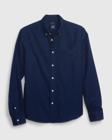
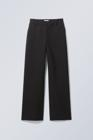
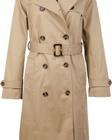
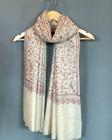
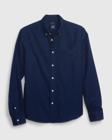
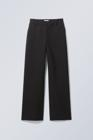
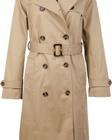
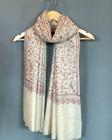
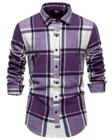
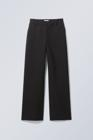
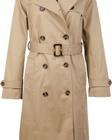
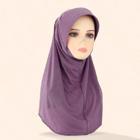
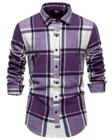
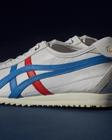
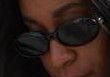
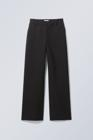
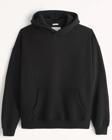
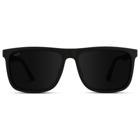
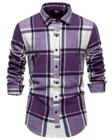
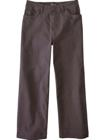
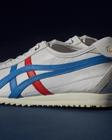
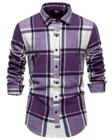
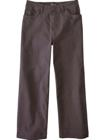
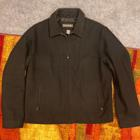
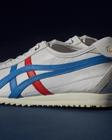
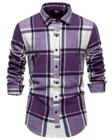
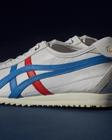
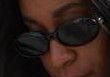
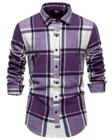
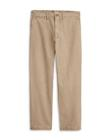
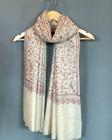
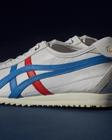
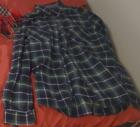
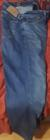
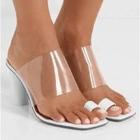
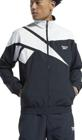
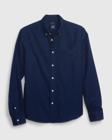
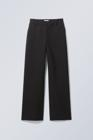
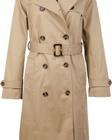
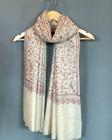
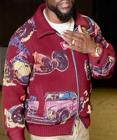
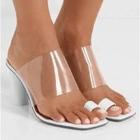
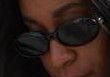
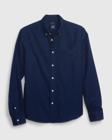
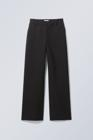
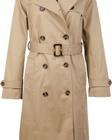
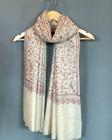
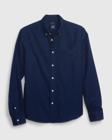
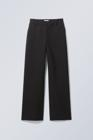
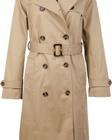
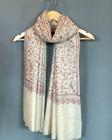
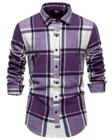
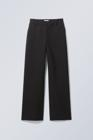
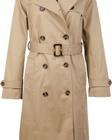
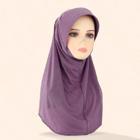
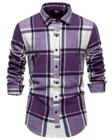
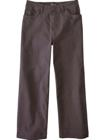
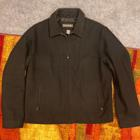
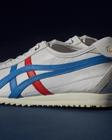
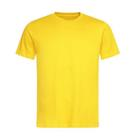
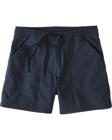
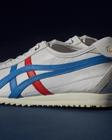
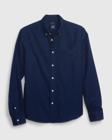
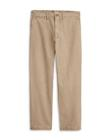
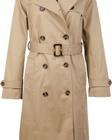
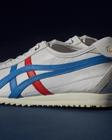
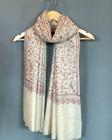
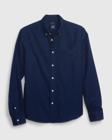
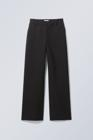
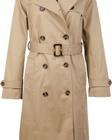
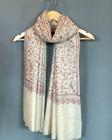
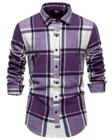
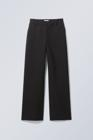
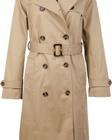
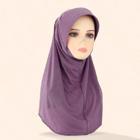
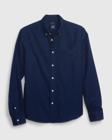
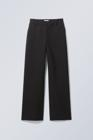
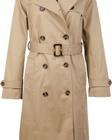
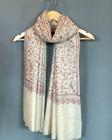
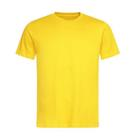
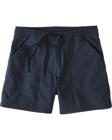
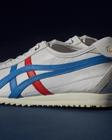
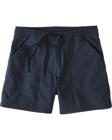
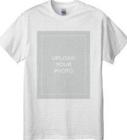
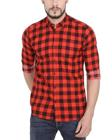
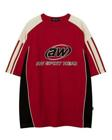
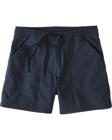
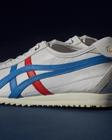
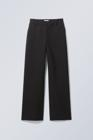
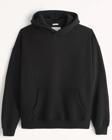
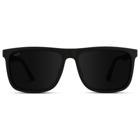
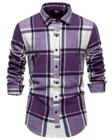
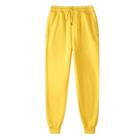
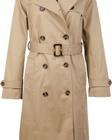
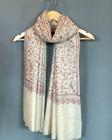
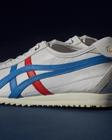
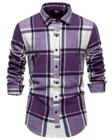
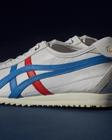
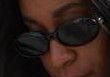
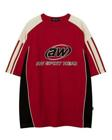
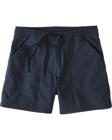
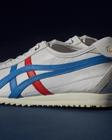
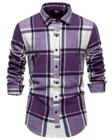
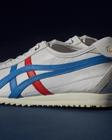
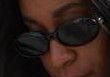
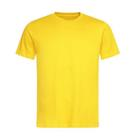
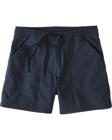
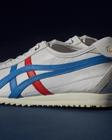
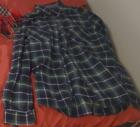
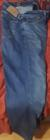
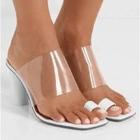
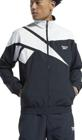
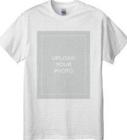
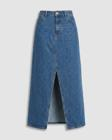
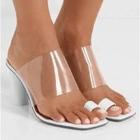
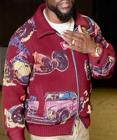
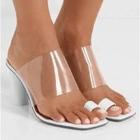
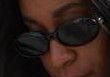
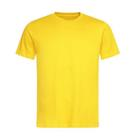
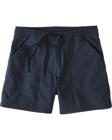
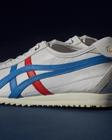
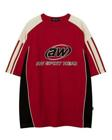
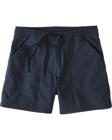
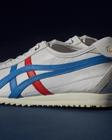
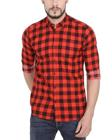
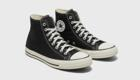
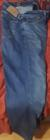
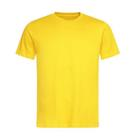
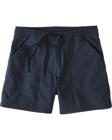
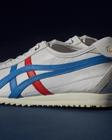
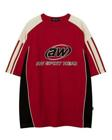
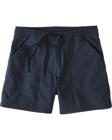
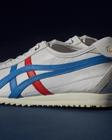
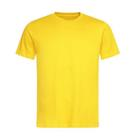
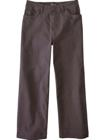
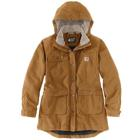
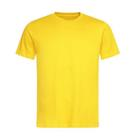
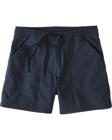
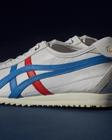
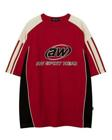
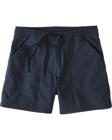
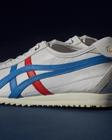
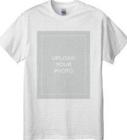
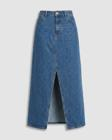
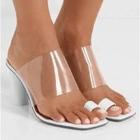
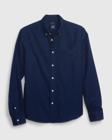
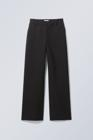
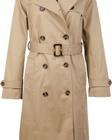
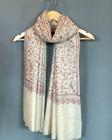
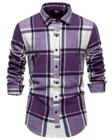
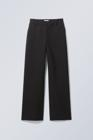
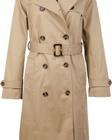
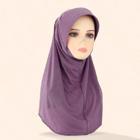
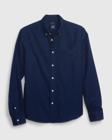
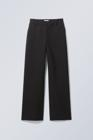
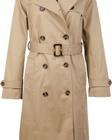
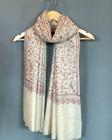
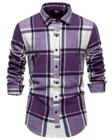
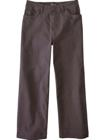
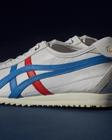
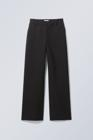
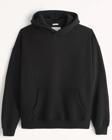
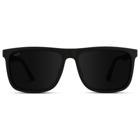
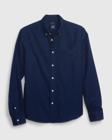
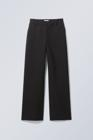
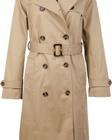
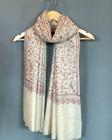
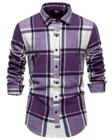
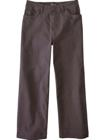
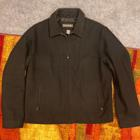
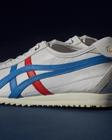
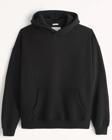
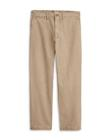
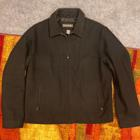
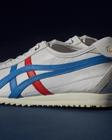
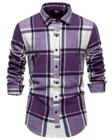
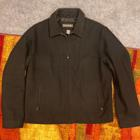
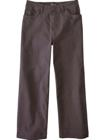
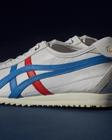
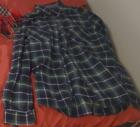
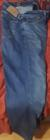
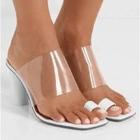
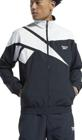
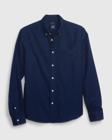
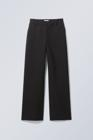
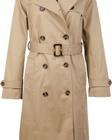
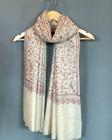
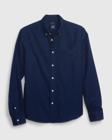
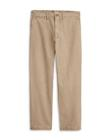
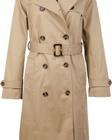
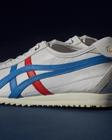
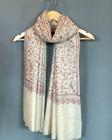
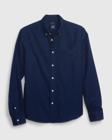
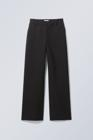
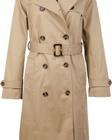
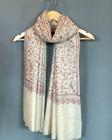
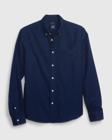
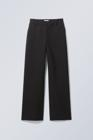
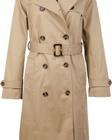
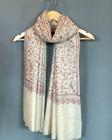
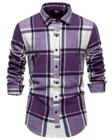
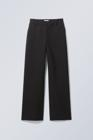
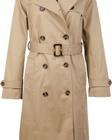
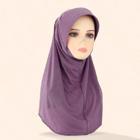
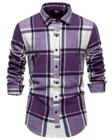
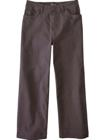
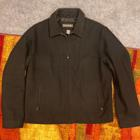
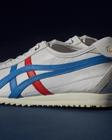
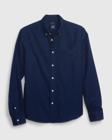
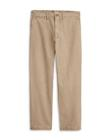
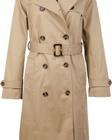
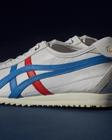
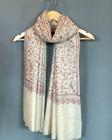
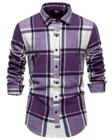
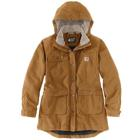
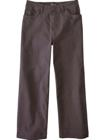
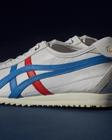
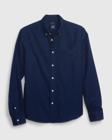
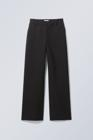
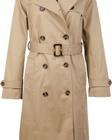
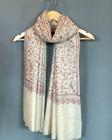
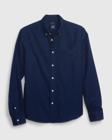
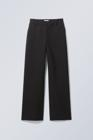
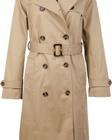
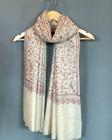
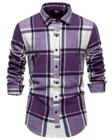
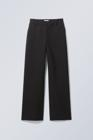
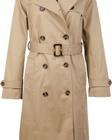
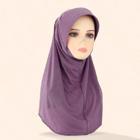
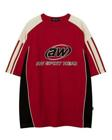
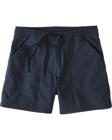
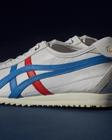
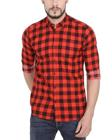
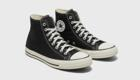
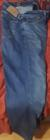
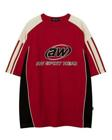
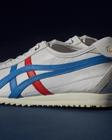
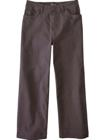
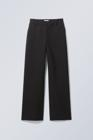
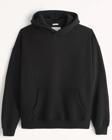
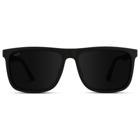
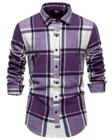
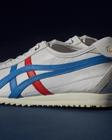
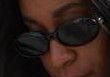
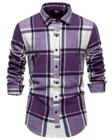
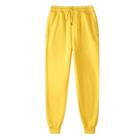
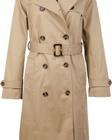
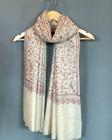
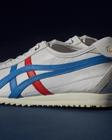
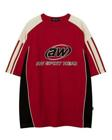
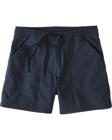
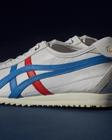
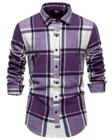
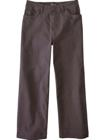
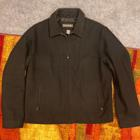
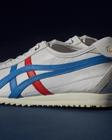
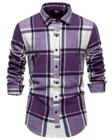
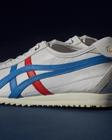
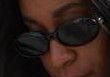
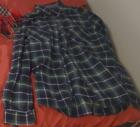
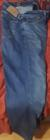
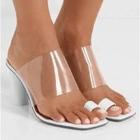
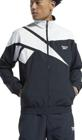
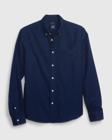
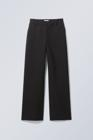
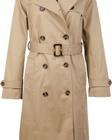
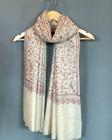
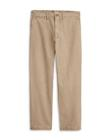
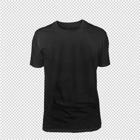
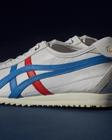
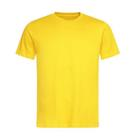
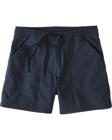
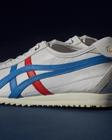
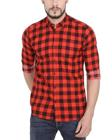
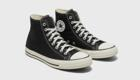
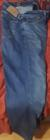
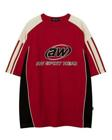
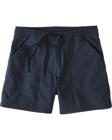
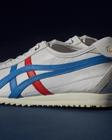
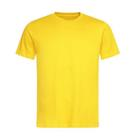
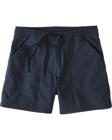
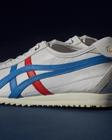
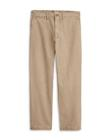
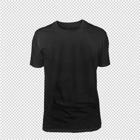
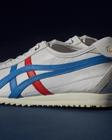
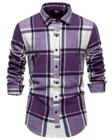
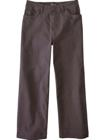
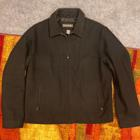
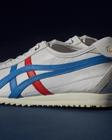
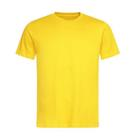
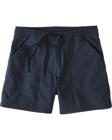
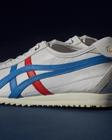
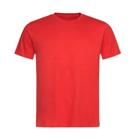
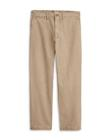
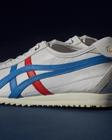
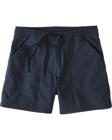
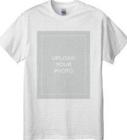
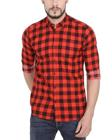
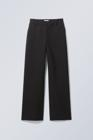
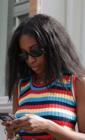
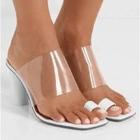
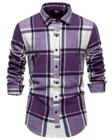
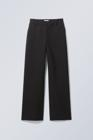
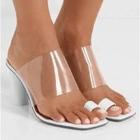
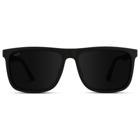
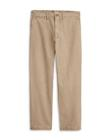
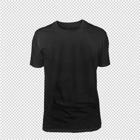
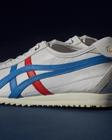
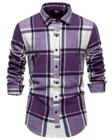
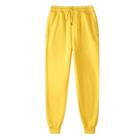
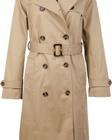
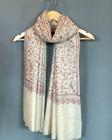
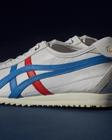
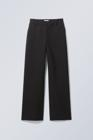
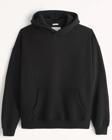
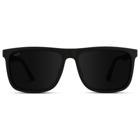
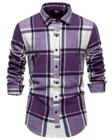
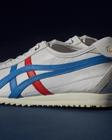
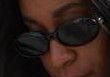
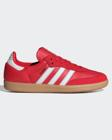
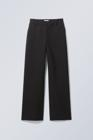
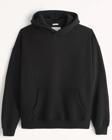
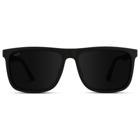
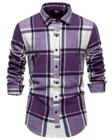
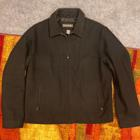
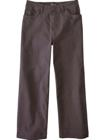
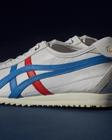
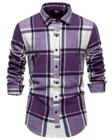
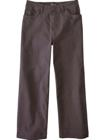
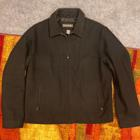
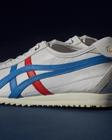
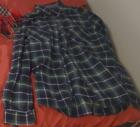
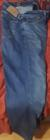
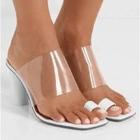
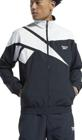
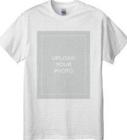
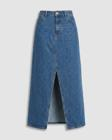
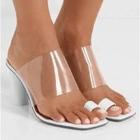
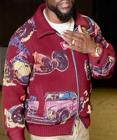
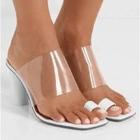
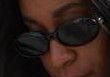
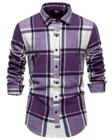
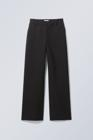
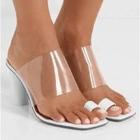
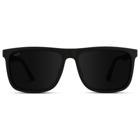
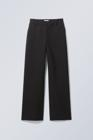
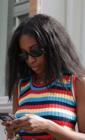
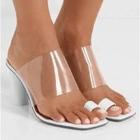
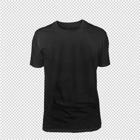
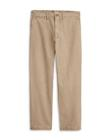
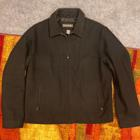
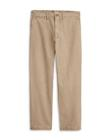
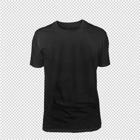
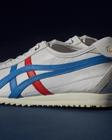
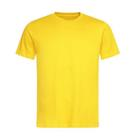
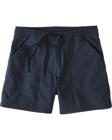
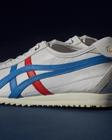
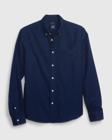
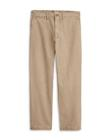
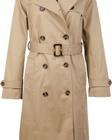
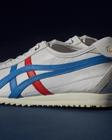
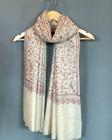
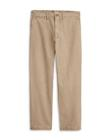
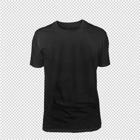
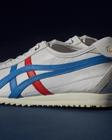
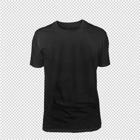
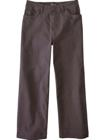
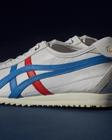
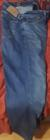
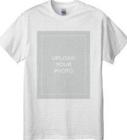
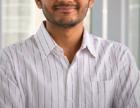
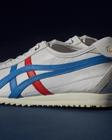
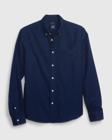
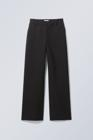
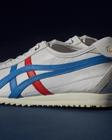
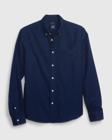
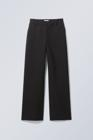
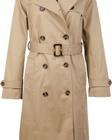
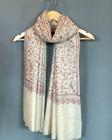
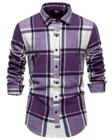
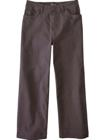
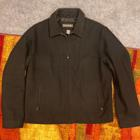
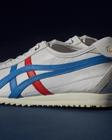
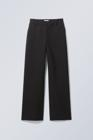
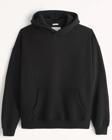
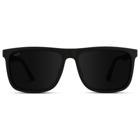
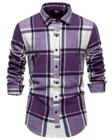
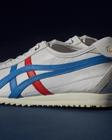
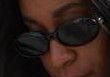
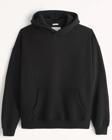
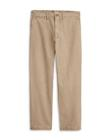
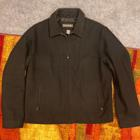
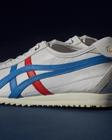
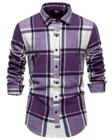
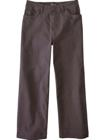
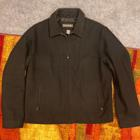
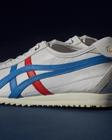
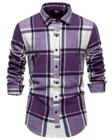
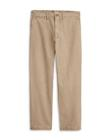
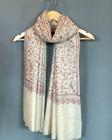
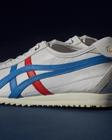
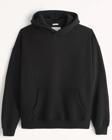
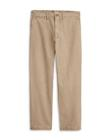
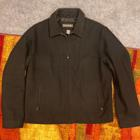
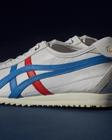
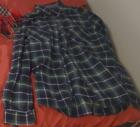
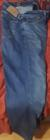
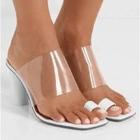
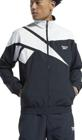
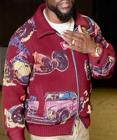
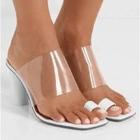
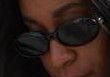
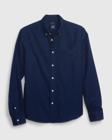
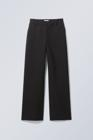
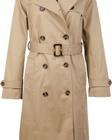
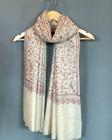
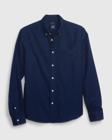
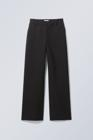
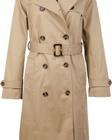
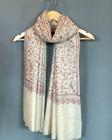
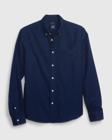
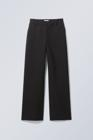
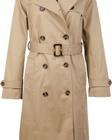
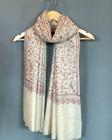
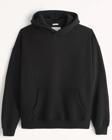
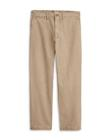
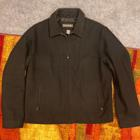
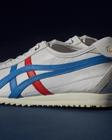
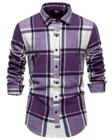
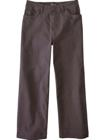
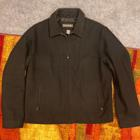
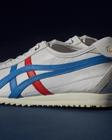
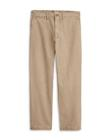
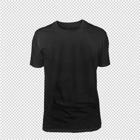
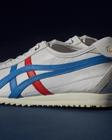
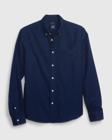
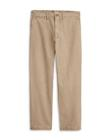
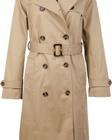
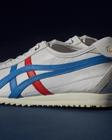
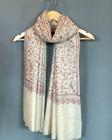
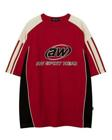
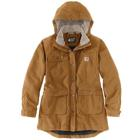
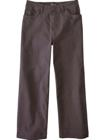
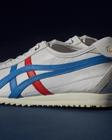
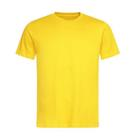
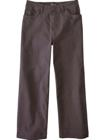
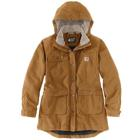
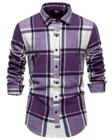
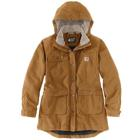
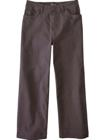
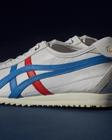
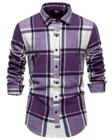
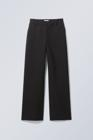
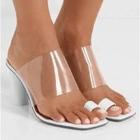
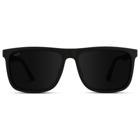
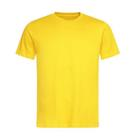
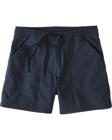
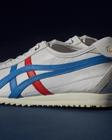
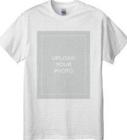
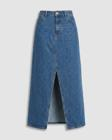
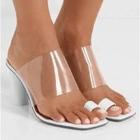
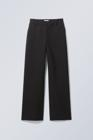
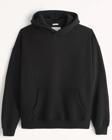
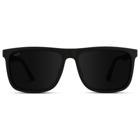
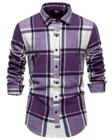
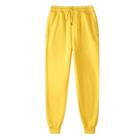
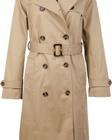
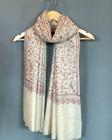
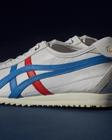
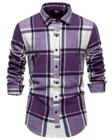
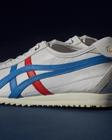
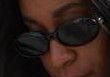
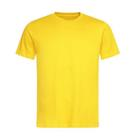
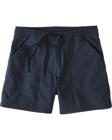
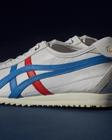
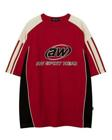
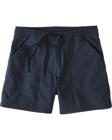
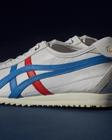
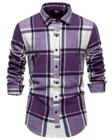
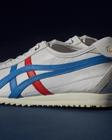
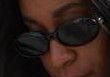
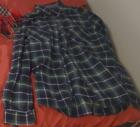
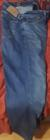
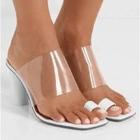
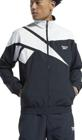
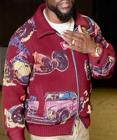
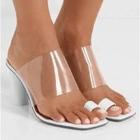
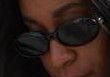
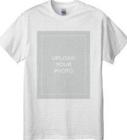
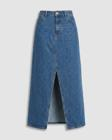
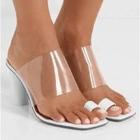
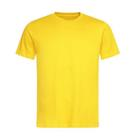
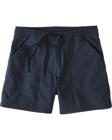
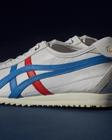
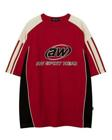
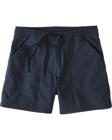
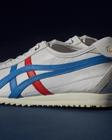
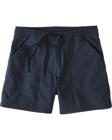
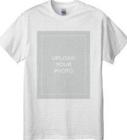
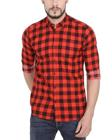
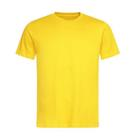
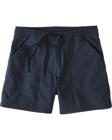
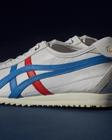
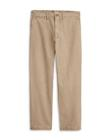
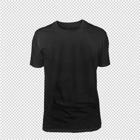
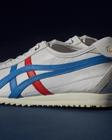
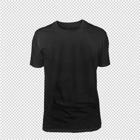
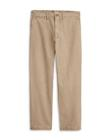
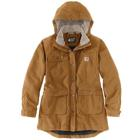
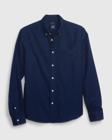
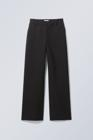
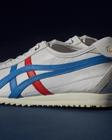
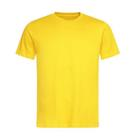
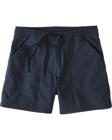
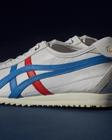
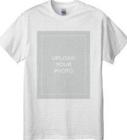
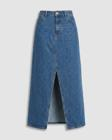
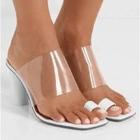
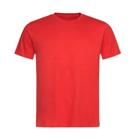
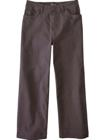
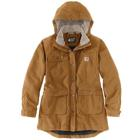
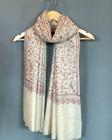
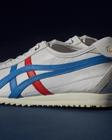
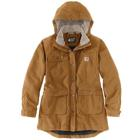
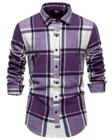
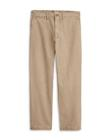
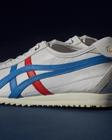
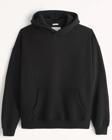
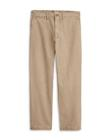
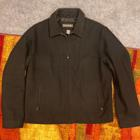
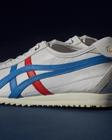
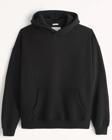
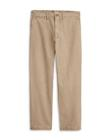
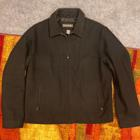
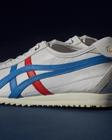
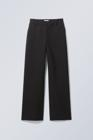
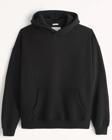
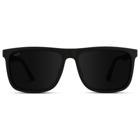
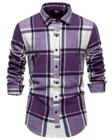
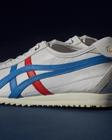
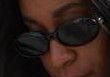
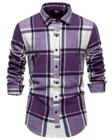
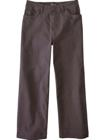
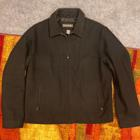
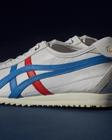
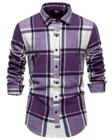
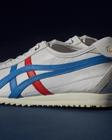
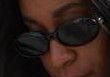
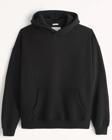
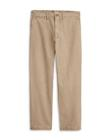
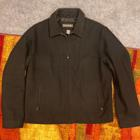
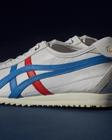
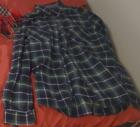
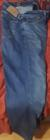
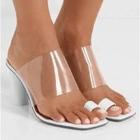
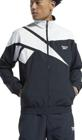
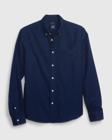
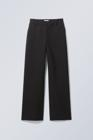
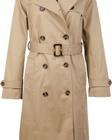
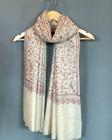
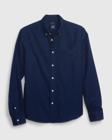
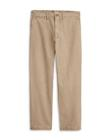
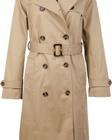
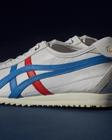
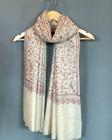
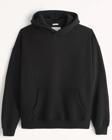
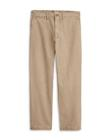
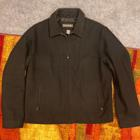
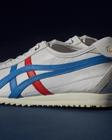
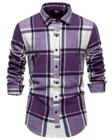
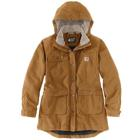
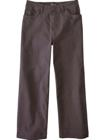
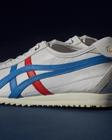
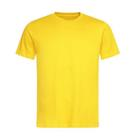
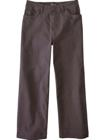
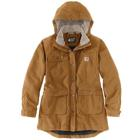
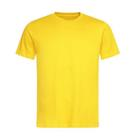
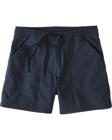
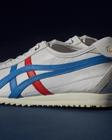
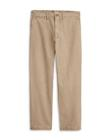
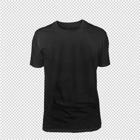
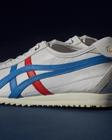
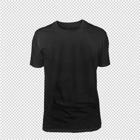
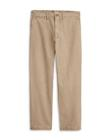
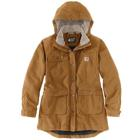
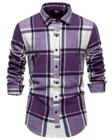
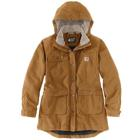
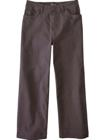
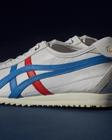
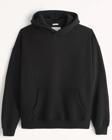
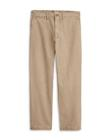
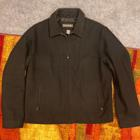
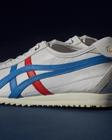
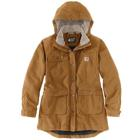
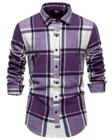
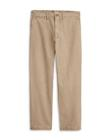
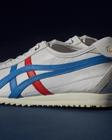
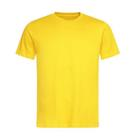
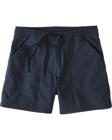
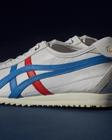
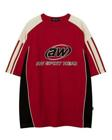
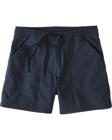
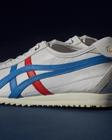
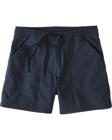
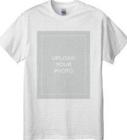
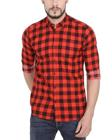
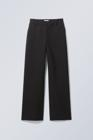
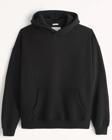
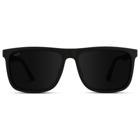
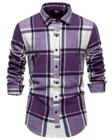
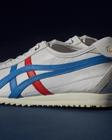
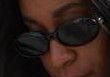
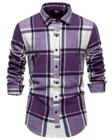
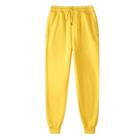
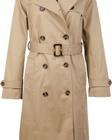
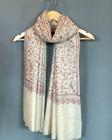
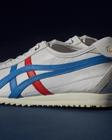
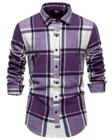
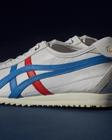
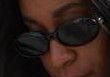
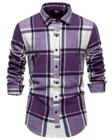
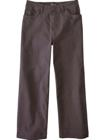
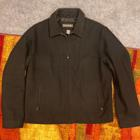
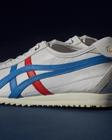
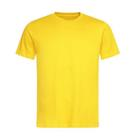
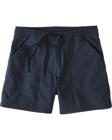
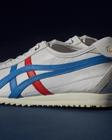
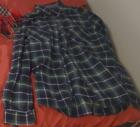
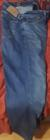
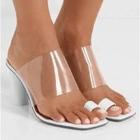
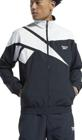
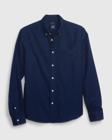
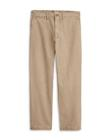
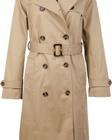
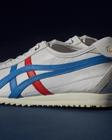
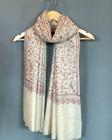
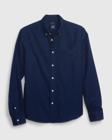
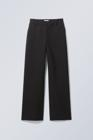
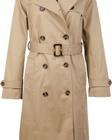
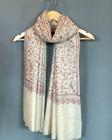
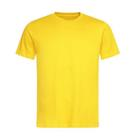
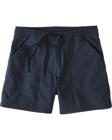
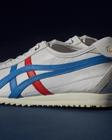
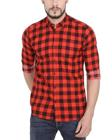
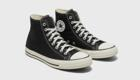
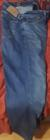
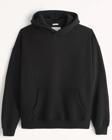
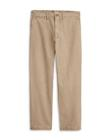
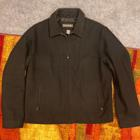
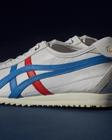
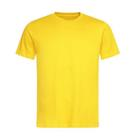
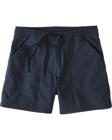
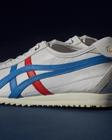
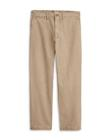
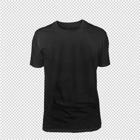
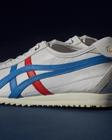
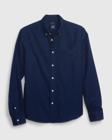
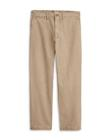
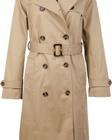
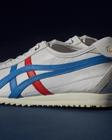
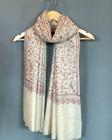
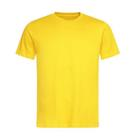
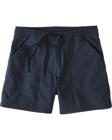
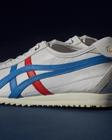
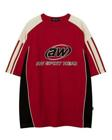
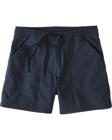
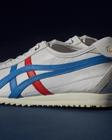
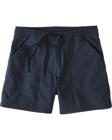
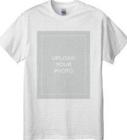
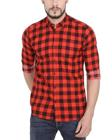
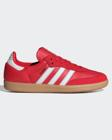
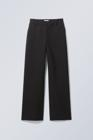
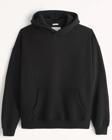
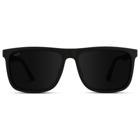
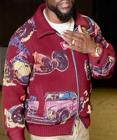
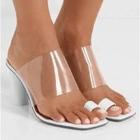
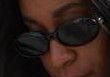
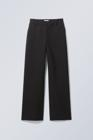
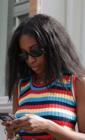
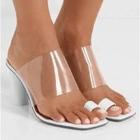
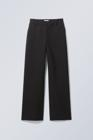
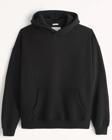
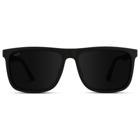
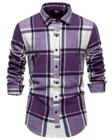
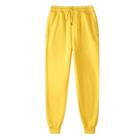
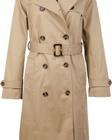
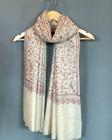
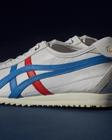
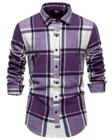
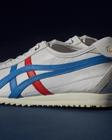
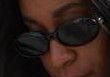
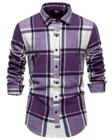
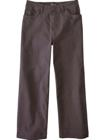
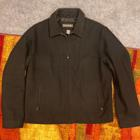
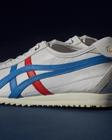
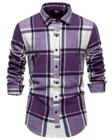
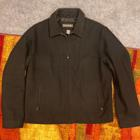
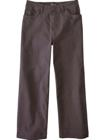
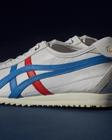
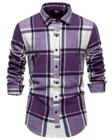
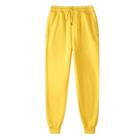
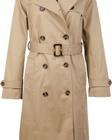
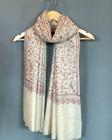
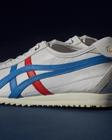
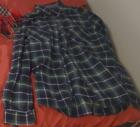
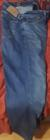
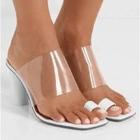
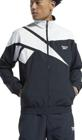
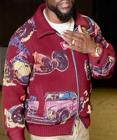
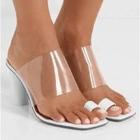
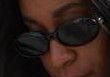
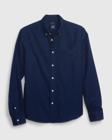
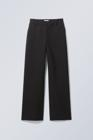
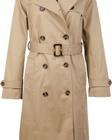
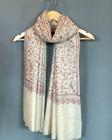
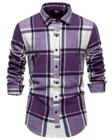
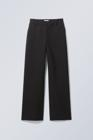
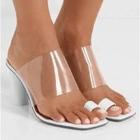
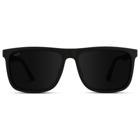
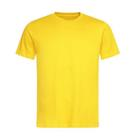
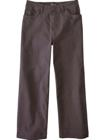
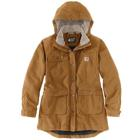
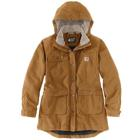
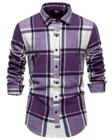
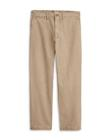
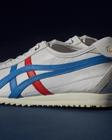
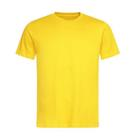
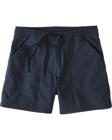
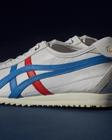
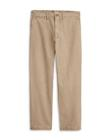
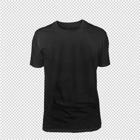
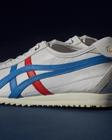
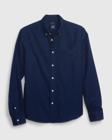
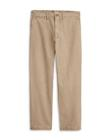
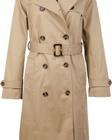
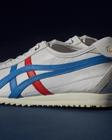
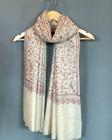
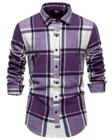
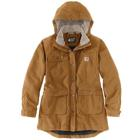
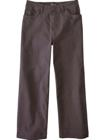
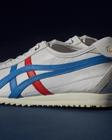
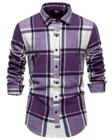
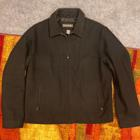
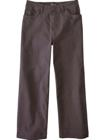
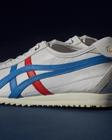
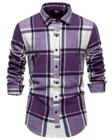
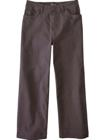
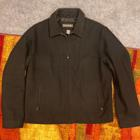
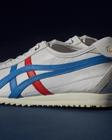

In [9]:
outfits_by_id = {o["id"]: o for o in outfits}


def top3_row(name: str, fx_id: str) -> str:
    s = suggest_scores.get((name, fx_id)) or {}
    if not s:
        return f"<tr><td style='font-weight:600'>{name}</td><td style='color:#999'>no result</td></tr>"
    cells = []
    for qid in ranked(s)[:3]:
        o = outfits_by_id.get(qid[2:])
        if o:
            cells.append(f"<div style='display:inline-block;vertical-align:top;margin-right:12px'><div style='font-size:12px'><b>{o['name'] or 'Unnamed'}</b> <span style='font-family:monospace;color:#0a7f42'>{s[qid]:.2f}</span></div>{outfit_image_html(o, size=40)}</div>")
    return f"<tr><td style='font-weight:600;white-space:nowrap;vertical-align:top'>{name}</td><td>{''.join(cells)}</td></tr>"


html = ["<h2>Prototype 25 — decision-model candidates vs Jev</h2>",
        f"<div style='color:#666'>Closet: {len(outfits)} outfits, {len(items)} items. Pod: RunPod RTX A6000 48 GB. Candidates: {', '.join(CANDIDATES)}.</div>",
        "<h3>Agreement with Jev</h3>", compare_df.to_html(index=False, float_format=lambda x: f"{x:.2f}")]
for fx in FIXTURES:
    w = fx["weather"]
    html.append(f"<h3 style='margin-top:24px'>{fx['id']}</h3><div style='color:#666;font-size:13px'>{w['temperature']}°C {w['condition']} · {fx['occasion']} · {fx['timeOfDay']} {fx['dayOfWeek']}{' · ' + fx['theme'] if fx.get('theme') else ''}</div>")
    html.append("<table style='border-collapse:collapse'>" + "".join(top3_row(n, fx["id"]) for n in CANDIDATES) + "</table>")
full_html = "".join(html)
display(HTML(full_html))

## 10. Save artefacts + gates

Same gates as nb24, measured against Jev: suggest top-1 in Jev's top 3 ≥ 75%, suggest Spearman ≥ 0.6, collection Spearman ≥ 0.6 (rank agreement; accept/reject at a fixed 0.5 isn't fair across differently calibrated models).

In [10]:
(OUT_DIR / "report.html").write_text("<!doctype html><html><head><meta charset='utf-8'><title>Prototype 25</title>"
    "<style>body{font-family:system-ui,-apple-system,sans-serif;padding:24px;max-width:1200px;margin:auto}table{border-collapse:collapse}td,th{padding:4px 8px;border:1px solid #eee}</style>"
    f"</head><body>{full_html}</body></html>")
pd.DataFrame([{"candidate": n, "fixture_id": f, "scores": json.dumps(s)} for (n, f), s in suggest_scores.items()]).to_csv(OUT_DIR / "suggest.csv", index=False)
pd.DataFrame([{"candidate": n, "collection": c, "outfit_id": q[2:], "score": v} for (n, c), s in coll_scores.items() for q, v in s.items()]).to_csv(OUT_DIR / "collections.csv", index=False)
compare_df.to_csv(OUT_DIR / "compare.csv", index=False)
print(f"Wrote {OUT_DIR / 'report.html'}\n")
for _, r in compare_df.iterrows():
    ok = [r["suggest_top1_in_jev_top3"] >= 0.75, r["suggest_spearman"] >= 0.6, (r["coll_spearman"] >= 0.6) if r["coll_spearman"] == r["coll_spearman"] else None]
    marks = " ".join("—" if v is None else ("PASS" if v else "fail") for v in ok)
    print(f"{r['candidate']:13s} top1∈top3 {r['suggest_top1_in_jev_top3']:.0%}  ρ {r['suggest_spearman']:.2f}  coll ρ {r['coll_spearman']:.2f}   [{marks}]")

Wrote prototypes/outputs/25/report.html

qwen3-8b      top1∈top3 80%  ρ 0.76  coll ρ 0.83   [PASS PASS PASS]
gemini-flash  top1∈top3 50%  ρ 0.68  coll ρ 0.88   [fail PASS PASS]
clm-prose     top1∈top3 40%  ρ 0.63  coll ρ 0.80   [fail PASS PASS]
clm-raw       top1∈top3 10%  ρ 0.16  coll ρ 0.03   [fail fail fail]
prismnli      top1∈top3 50%  ρ 0.05  coll ρ 0.63   [fail fail PASS]
clm-choice    top1∈top3 0%  ρ -0.09  coll ρ nan   [fail fail —]


### Reading the results

- **Agreement is not accuracy.** Jev is the reference because it's in production, not because it's right. Where they disagree, the report decides: whose #1 would you actually wear?
- **Low Spearman but good top-1** is fine for suggest (only the top few are shown). The reverse is not.
- **Collections:** if CLM accepts far more or fewer outfits than Jev, the 0.5 threshold may need a per-model value rather than a different model.
- **Speed:** CLM is an embedding model with small heads, so it should be much faster than Jev over the network. A p95 over 1 s on a warm GPU means something's wrong in the serving setup, not the model.

## 11. Qwen-Image — just make a few images

After the CLM run, stop CLM and start Qwen-Image on the pod (vLLM-Omni, #296 Phase 3: `vllm serve Qwen/Qwen-Image-2.1 --omni --port 8091 --api-key <key>`). Then set `IMAGE_URL=http://localhost:8091/v1` (tunnel with `ssh -L 8091:localhost:8091 …`) and `IMAGE_API_KEY`. Uses the same multipart request as Vastra (#352): garment photos first, person photo last. The person photo is your most recent try-on photo in the closet (the one the app uses), unless `prototypes/inputs/person.jpg` exists.

Person photo: .closet/users/self/images/user/a7O3a3PRc4KCocOYKsUJQ.jpg exists=True


Toronto Evening Out            48.9s  peak 48162.0 MB


The Eccentric Urbanite         50.0s  peak 48100.0 MB


Rugged Holiday Outdoor         13.3s  peak 48146.0 MB



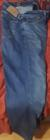
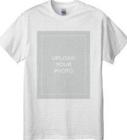
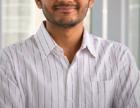
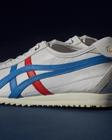
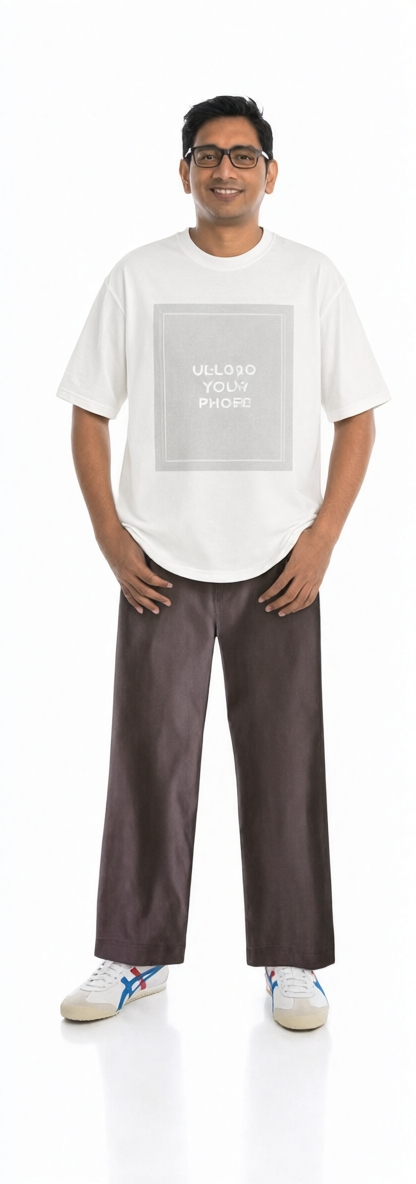
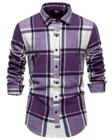
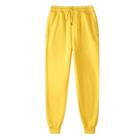
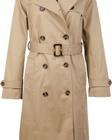
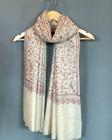
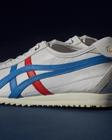
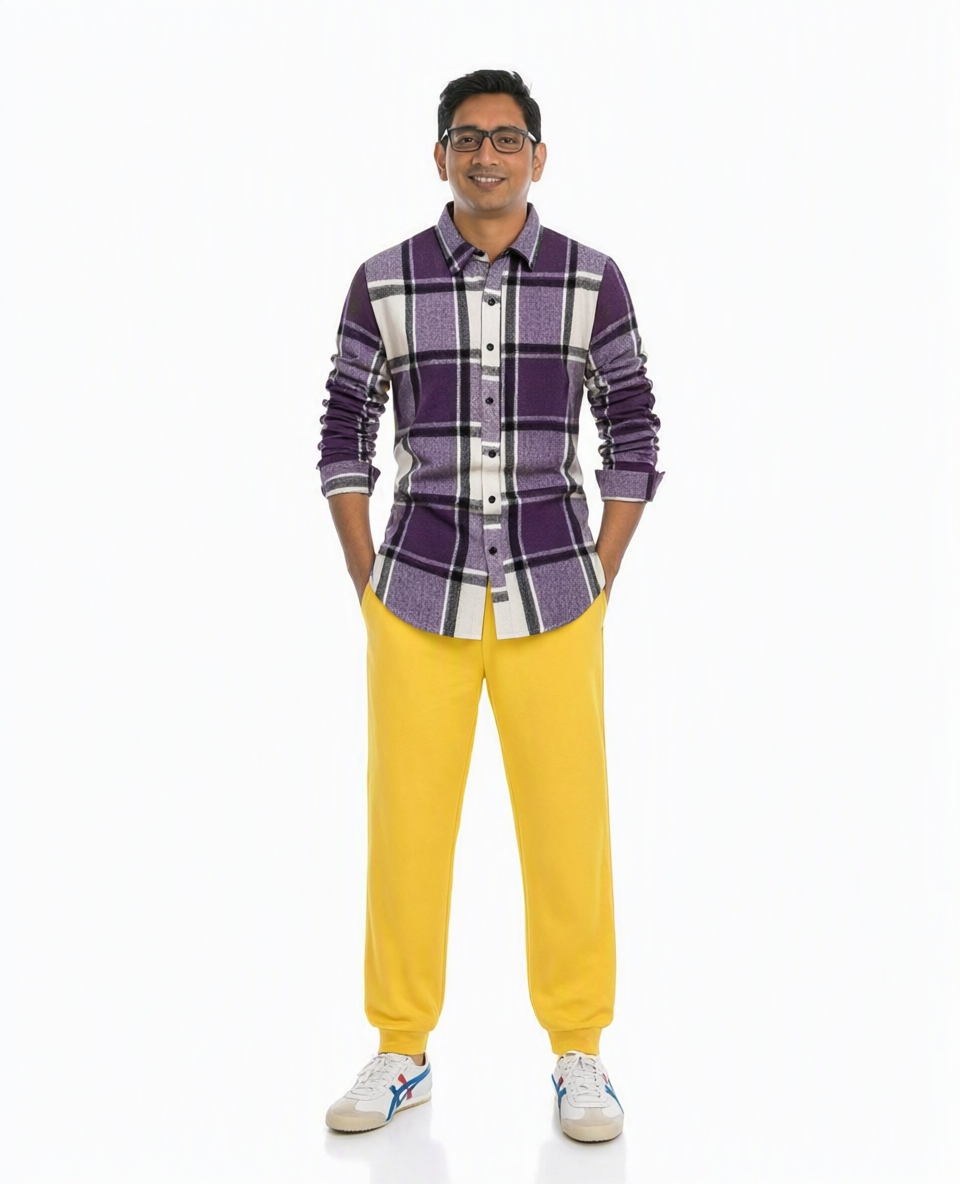
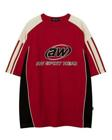
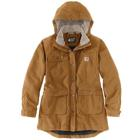
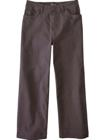
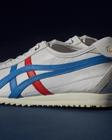
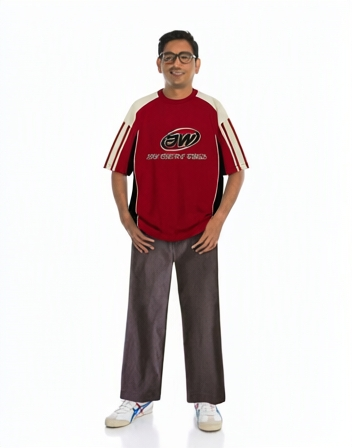

In [6]:
IMAGE_URL = os.environ.get("IMAGE_URL", "")
IMAGE_KEY = os.environ.get("IMAGE_API_KEY", "")
PERSON = Path(os.environ.get("NB25_PERSON", str(REPO_ROOT / "prototypes" / "inputs" / "person.jpg")))
if not PERSON.exists():
    # Fall back to the closet's own try-on photo (what POST /api/tryon uses).
    row = _rows(CLOSET_DB, "SELECT image_uri FROM user_photos WHERE user_id = ? ORDER BY is_primary DESC, created_at DESC LIMIT 1", (ACTIVE_USER,))
    if row:
        PERSON = next((p for p in (CLOSET_DATA_DIR / "users" / str(ACTIVE_USER) / row[0]["image_uri"], CLOSET_DATA_DIR / row[0]["image_uri"]) if p.exists()), PERSON)
print(f"Person photo: {PERSON} exists={PERSON.exists()}")


def qwen_edit(prompt: str, images: list[bytes], *, steps: int = 40, timeout_s: int = 600) -> tuple[bytes | None, float, str]:
    boundary = "----nb24" + str(time.time_ns())
    parts = []
    def field(name, value):
        parts.append(f"--{boundary}\r\nContent-Disposition: form-data; name=\"{name}\"\r\n\r\n{value}\r\n".encode())
    for k, v in {"model": "Qwen/Qwen-Image-2.1", "prompt": prompt, "n": "1", "response_format": "b64_json", "output_format": "jpeg", "num_inference_steps": str(steps)}.items():
        field(k, v)
    for i, img in enumerate(images):
        parts.append(f"--{boundary}\r\nContent-Disposition: form-data; name=\"image\"; filename=\"ref-{i + 1}.jpg\"\r\nContent-Type: image/jpeg\r\n\r\n".encode() + img + b"\r\n")
    parts.append(f"--{boundary}--\r\n".encode())
    headers = {"Content-Type": f"multipart/form-data; boundary={boundary}"}
    if IMAGE_KEY:
        headers["Authorization"] = f"Bearer {IMAGE_KEY}"
    req = urllib.request.Request(f"{IMAGE_URL}/images/edits", data=b"".join(parts), method="POST", headers=headers)
    t0 = time.perf_counter()
    try:
        with urllib.request.urlopen(req, timeout=timeout_s) as resp:
            payload = json.loads(resp.read())
        return base64.b64decode(payload["data"][0]["b64_json"]), time.perf_counter() - t0, f"peak {payload.get('metrics', {}).get('peak_memory_mb', '?')} MB"
    except Exception as e:
        return None, time.perf_counter() - t0, f"{type(e).__name__}: {e}"


def item_bytes(it: dict) -> bytes | None:
    path = next((p for p in (CLOSET_DATA_DIR / "users" / str(ACTIVE_USER) / it["image_uri"], CLOSET_DATA_DIR / it["image_uri"]) if p.exists()), None)
    return path.read_bytes() if path else None


image_html = []
if IMAGE_URL and PERSON.exists():
    for o in outfits[:3]:
        garments = [b for b in (item_bytes(items_by_id[i]) for i in o["item_ids"][:3] if i in items_by_id) if b]
        prompt = (f"Images 1–{len(garments)} are clothing items; the LAST image is the person. "
                  "Dress the person in these clothes. Keep their face, body, pose and background exactly the same.")
        out, secs, note = qwen_edit(prompt, garments + [PERSON.read_bytes()])
        print(f"{o['name']:30s} {secs:.1f}s  {note}")
        if out:
            image_html.append(f"<div><b>{o['name']}</b> · {secs:.1f}s · {note}{outfit_image_html(o, size=48)}"
                              f"<img src='data:image/jpeg;base64,{base64.b64encode(out).decode()}' style='max-width:320px;border-radius:6px'/></div>")
    if image_html:
        block = "<h2>Qwen-Image samples</h2><div style='display:grid;grid-template-columns:repeat(auto-fill,minmax(320px,1fr));gap:16px'>" + "".join(image_html) + "</div>"
        display(HTML(block))
        (OUT_DIR / "report.html").write_text((OUT_DIR / "report.html").read_text().replace("</body>", block + "</body>"))
else:
    print("Skipped: set IMAGE_URL and add prototypes/inputs/person.jpg")